# Phase 9 - Clasificación de Patrón Parcial + Regresión de Completitud

Objetivo multitarea:
- **Clasificar** el patrón parcial en formación (`class 0 = ruido/no-informativo`, `1..K = patrones informativos`).
- **Regresar** el porcentaje de completitud (`0.0-1.0`) en segmentos informativos.

Entrenamiento sobre muestras intrasegmento (por barra), para que la completitud tenga señal real de progreso.

In [1]:
from pathlib import Path
import json
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

ROOT = Path('.')
PHASE9 = ROOT / 'phases/phase09_multitask_patterns'
RUN_SCRIPT = PHASE9 / 'run_phase9_multitask_partial_pattern.py'
OUT_DIR = PHASE9 / 'output_phase9_partial_pattern_GBPUSD'
SUMMARY_JSON = OUT_DIR / 'GBPUSD_phase9_summary.json'
HISTORY_CSV = OUT_DIR / 'GBPUSD_phase9_train_history.csv'
PRED_CSV = OUT_DIR / 'GBPUSD_phase9_test_predictions.csv'

In [2]:
subprocess.run(['python', str(RUN_SCRIPT)], check=True)
print('Ejecutado:', RUN_SCRIPT)

Saved summary: ./phases/phase09_multitask_patterns/output_phase9_partial_pattern_GBPUSD/GBPUSD_phase9_summary.json
Test metrics: {'acc': 0.3874694512330593, 'f1_macro_all': 0.3922383190655909, 'f1_macro_informative': 0.7622175381337685, 'mae_progress': 0.062203552573919296, 'rmse_progress': 0.0878884345293045, 'mae_progress_early': 0.06172632798552513, 'n_informative': 1187}


Ejecutado: ./phases/phase09_multitask_patterns/run_phase9_multitask_partial_pattern.py


In [3]:
summary = json.loads(SUMMARY_JSON.read_text())
history = pd.read_csv(HISTORY_CSV)
pred = pd.read_csv(PRED_CSV)

print('model_tag:', summary['model_tag'])
print('n_samples:', summary['n_samples'])

pd.DataFrame([summary['test_metrics']]).T.rename(columns={0:'value'}).round(4)

model_tag: phase9_multitask_partial_pattern_cls_plus_progress
n_samples: {'total': 30511, 'train': 21526, 'val': 4484, 'test': 4501, 'test_informative': 1187}


,value
acc,0.3875
f1_macro_all,0.3922
f1_macro_informative,0.7622
mae_progress,0.0622
rmse_progress,0.0879
mae_progress_early,0.0617
n_informative,1187.0000


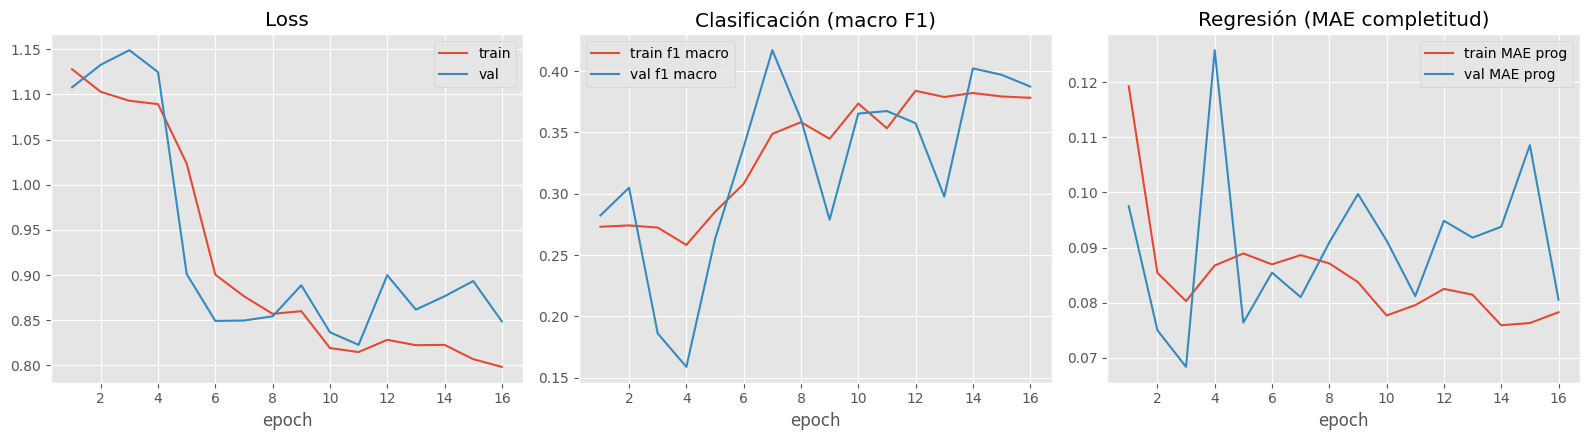

In [4]:
plt.style.use('ggplot')
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].plot(history['epoch'], history['train_loss'], label='train')
axes[0].plot(history['epoch'], history['val_loss'], label='val')
axes[0].set_title('Loss')
axes[0].set_xlabel('epoch')
axes[0].legend()

axes[1].plot(history['epoch'], history['train_f1_macro_all'], label='train f1 macro')
axes[1].plot(history['epoch'], history['val_f1_macro_all'], label='val f1 macro')
axes[1].set_title('Clasificación (macro F1)')
axes[1].set_xlabel('epoch')
axes[1].legend()

axes[2].plot(history['epoch'], history['train_mae_progress'], label='train MAE prog')
axes[2].plot(history['epoch'], history['val_mae_progress'], label='val MAE prog')
axes[2].set_title('Regresión (MAE completitud)')
axes[2].set_xlabel('epoch')
axes[2].legend()

plt.tight_layout()
plt.show()

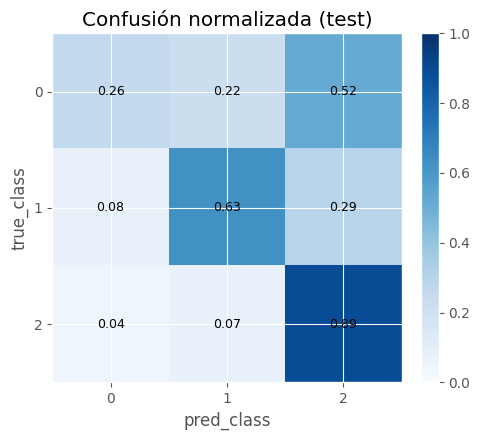

In [5]:
# Confusion matrix (todas las clases)
y_true = pred['y_class'].to_numpy()
y_pred = pred['pred_class'].to_numpy()
labels = sorted(np.unique(np.concatenate([y_true, y_pred])))
cm = confusion_matrix(y_true, y_pred, labels=labels)
cm_norm = cm / np.clip(cm.sum(axis=1, keepdims=True), 1, None)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(cm_norm, cmap='Blues', vmin=0, vmax=1)
ax.set_title('Confusión normalizada (test)')
ax.set_xlabel('pred_class')
ax.set_ylabel('true_class')
ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels)
ax.set_yticklabels(labels)

for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, f"{cm_norm[i, j]:.2f}", ha='center', va='center', fontsize=9, color='black')

plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

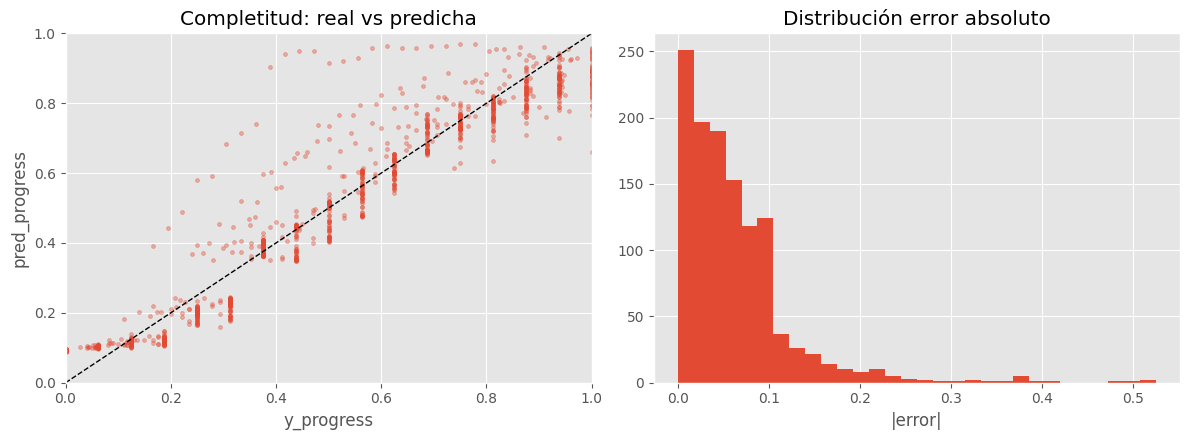

MAE completitud global: 0.0622
MAE completitud early (<0.5): 0.0617


In [6]:
# Análisis de completitud solo en muestras informativas
inf = pred[pred['reg_mask'] == 1].copy()
inf['abs_err'] = (inf['pred_progress'] - inf['y_progress']).abs()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(inf['y_progress'], inf['pred_progress'], s=8, alpha=0.4)
axes[0].plot([0, 1], [0, 1], '--', color='black', linewidth=1)
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1)
axes[0].set_xlabel('y_progress')
axes[0].set_ylabel('pred_progress')
axes[0].set_title('Completitud: real vs predicha')

axes[1].hist(inf['abs_err'], bins=30)
axes[1].set_xlabel('|error|')
axes[1].set_title('Distribución error absoluto')

plt.tight_layout()
plt.show()

mae_global = inf['abs_err'].mean()
mae_early = inf.loc[inf['y_progress'] < 0.5, 'abs_err'].mean()
print('MAE completitud global:', round(float(mae_global), 4))
print('MAE completitud early (<0.5):', round(float(mae_early), 4))

In [7]:
# MAE por bin de progreso
inf = pred[pred['reg_mask'] == 1].copy()
inf['abs_err'] = (inf['pred_progress'] - inf['y_progress']).abs()
inf['prog_bin'] = pd.cut(inf['y_progress'], bins=np.linspace(0,1,6), include_lowest=True)
mae_bin = inf.groupby('prog_bin', observed=False)['abs_err'].mean().reset_index()
mae_bin

,prog_bin,abs_err
0,"(-0.001, 0.2]",0.052804
1,"(0.2, 0.4]",0.069316
2,"(0.4, 0.6]",0.066520
3,"(0.6, 0.8]",0.046201
4,"(0.8, 1.0]",0.075222


## Lectura rápida

- `f1_macro_informative` mide qué tan bien distingue los patrones informativos entre sí.
- `mae_progress` mide el error promedio del porcentaje de avance del patrón.
- `mae_progress_early` es la métrica más crítica para detección temprana.
